# Supervised learning: Will price go down?  

Based on the identification of a pattern in the price dynamics of soybean futures traded on the Chicago Board of Trade (CBOT), this project aims to compare the performance of different supervised machine learning algorithms to determine whether the price will experience a significant decline during a specific month.

The project will rely on data collected from various sources, including the United States Department of Agriculture (USDA), which provides historical data on soybean production, stocks, and forecasts dating back to 1990. Additionally, soybean futures price data was obtained from the Investing.com website.

The main objective is to predict, with a certain degree of accuracy, whether soybean futures prices will decline during July. Rather than approaching this problem as a regression task, it is framed as a classification problem: determining whether the price will decrease by more than a specified percentage.

To achieve this, several well-established supervised machine learning algorithms will be implemented and their predictive performance compared in order to identify the most suitable model for this task.







## Exploring data

Import several libraries and data i will use to analize them and for getting a first impression

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
p = pd.read_csv('/content/p.csv')
df_final = pd.read_csv('/content/df_final.csv')

### Dataset p

Here it is the dataset which contains the monthly price variation for soybean futures as its main feature, but it also includes the futures price on the last day of each month.

In [3]:
p.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 429 entries, 0 to 428
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   change  429 non-null    float64
 1   price   429 non-null    float64
 2   year    429 non-null    int64  
 3   month   429 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 13.5 KB


In [4]:
p.head()

,change,price,year,month
0,0.45,1006.25,2025,10
1,-3.38,1001.75,2025,9
2,7.80,1036.75,2025,8
3,-6.10,961.75,2025,7
4,-1.21,1024.25,2025,6


It can be observed that there are certain months in which the average price change tends to differ from zero. This project will focus specifically on those months with a negative average price change, particularly July, which exhibits a mean price change of -3.5% and a median of -3.1%. The median is also considered to provide a more robust measure given the relatively small number of observations.

What stands out is the substantial difference between July's average price change and that of the other months, with September being the only month showing a somewhat similar pattern, although its average decline is not as pronounced.

In other words, there appears to be a tendency for soybean futures prices to decline during July. The remaining challenge is to determine when this decline actually occurs and how it can be predicted.

In [5]:
p[['change','month']].groupby(by='month').agg(['mean','median','min','max','count']).sort_values(by=('change','mean'))

change                           
           mean median    min    max count
month                                     
7     -3.609444 -3.180 -32.87  13.02    36
9     -2.225000 -2.035 -21.55  14.20    36
8     -0.642222 -1.340 -13.28  11.74    36
6      0.241944 -0.540 -15.38  17.71    36
5      0.251944 -0.165 -21.28  10.67    36
1      0.631714  0.920 -12.75  12.17    35
3      1.083611  1.710 -21.34   9.29    36
12     1.342857 -0.290  -9.31  12.68    35
10     1.413889  1.015 -11.91  17.28    36
4      1.685278  0.410  -5.73  12.85    36
2      2.141389  1.215 -11.25  19.57    36
11     2.232857  2.160  -7.11  15.24    35

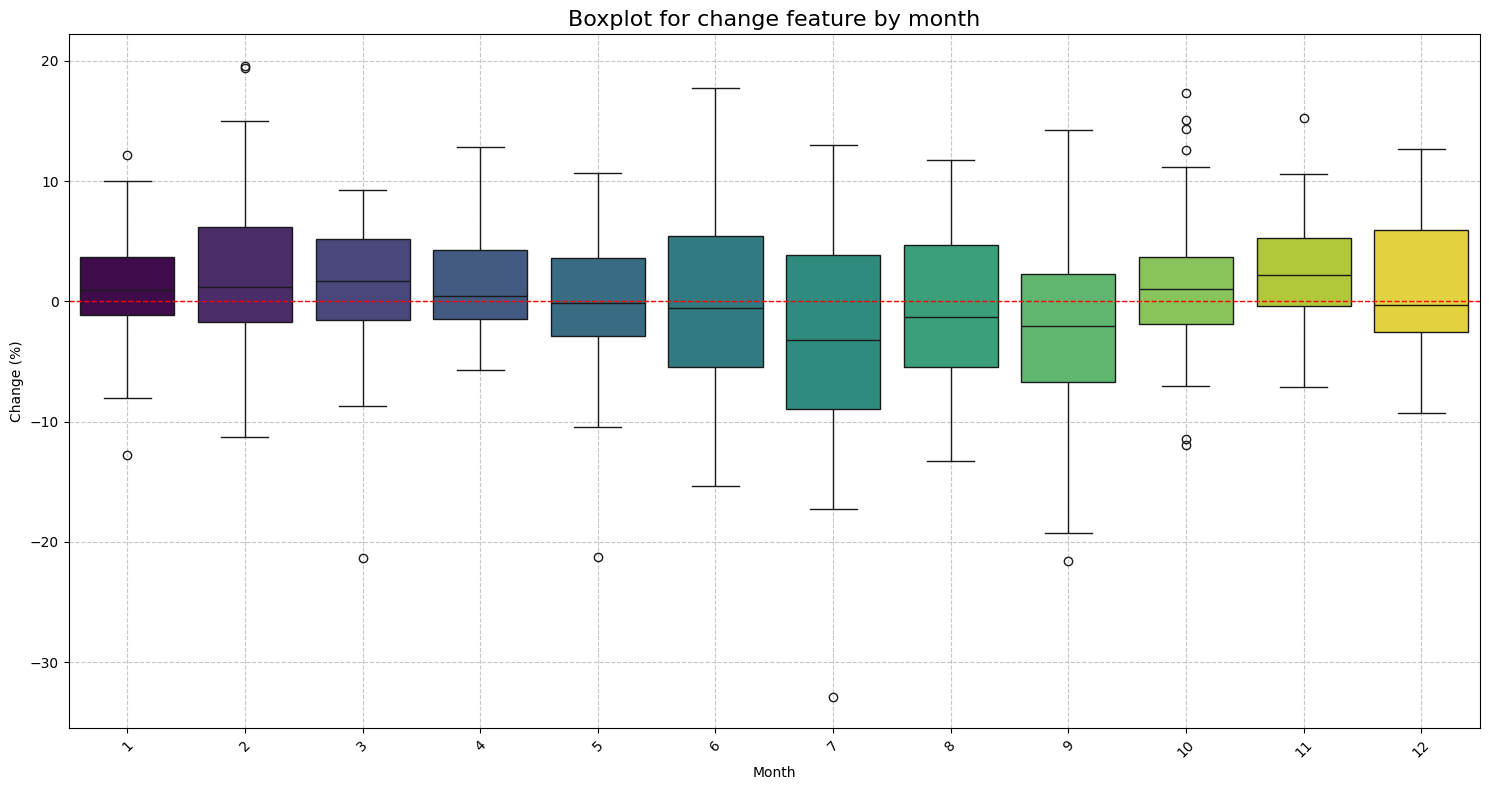

In [6]:
plt.figure(figsize=(15, 8))
sns.boxplot(x='month', y='change', data=p,hue= 'month',legend=False, palette='viridis')
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.title('Boxplot for change feature by month', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Change (%)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

A useful way to assess whether the mean is significantly different from zero is to calculate confidence intervals. In this case, 95% confidence intervals are constructed using bootstrap resampling with replacement. The results confirm that the mean price change for July is negative, indicating a clear tendency for soybean futures prices to decline during this month of the year.

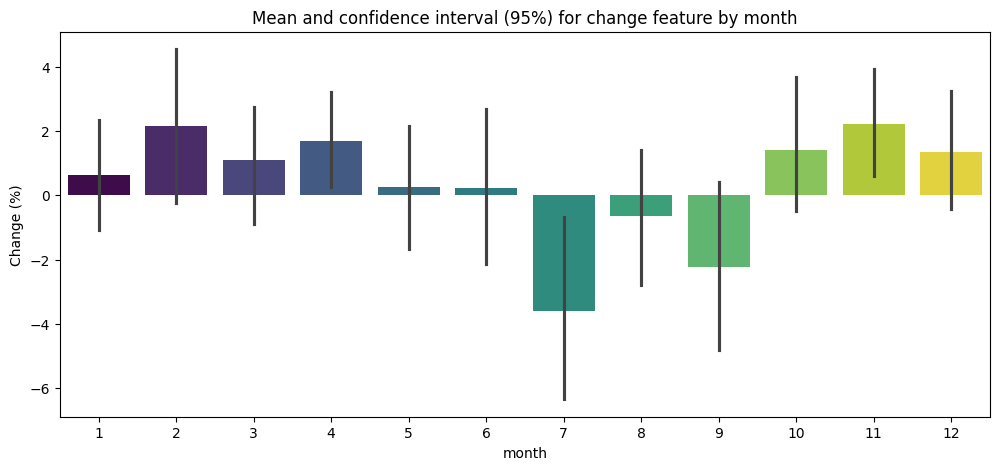

In [7]:
plt.figure(figsize=(12,5))
sns.barplot(data=p,x='month',y='change',palette='viridis',hue='month',legend=False,seed=21)
plt.ylabel('Change (%)')
plt.title('Mean and confidence interval (95%) for change feature by month')
plt.show()

It is worth noting that soybean futures prices declined by more than 3% in approximately half of the observed years. This suggests that the negative average is not merely driven by a few exceptionally large declines, but rather reflects a recurring pattern of price decreases during July.

To put this into perspective, prices fell by more than 5% in 44% of the observed years during July, compared to just 15.8% across all other months. Similarly, declines exceeding 10% occurred in 22% of the observed years in July, compared to approximately 5% during the rest of the year.

In other words, significant declines in soybean futures prices occur considerably more frequently in July than in any other period of the year.

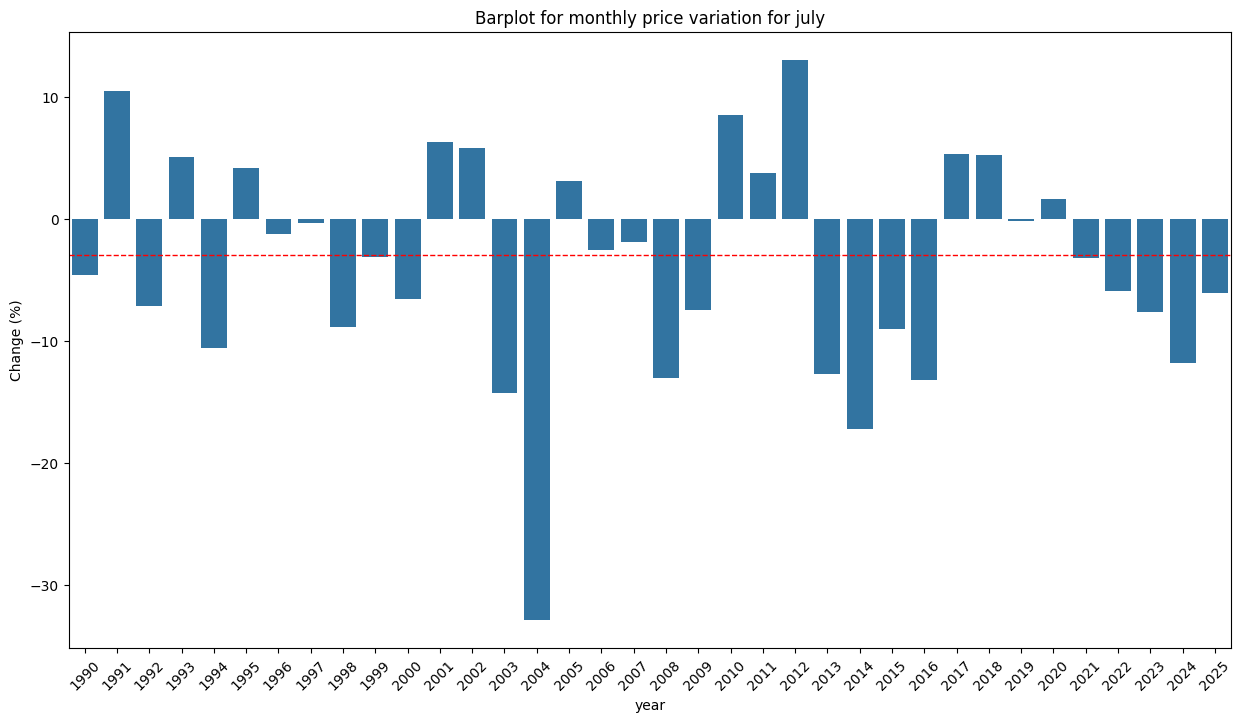

In [8]:
plt.figure(figsize=(15,8))
sns.barplot(x='year',y='change', data = p[p.month == 7])
plt.axhline(-3, color='red', linestyle='--', linewidth=1)
plt.title('Barplot for monthly price variation for july')
plt.xticks(rotation=45)
plt.ylabel('Change (%)')
plt.show()

In [9]:
true_5 = len(p[(p.change <= -5)&(p.month == 7)])
all_5 = len(p[(p.change < -5)&(p.month != 7)])
true_10 = len(p[(p.change <= -10)&(p.month == 7)])
all_10 = len(p[(p.change < -10)&(p.month != 7)])

print('Proportion of years below 5% (july):',true_5/len(p[p.month==7]))
print('Proportion of years below 5% (all):',all_5/len(p[p.month!=7]))
print('-------------------------------------------------------------------')
print('Proportion of years below 10% (july):',true_10/len(p[p.month==7]))
print('Proportion of years below 10% (all):',all_10/len(p[p.month!=7]))

Proportion of years below 5% (july): 0.4444444444444444
Proportion of years below 5% (all): 0.15776081424936386
-------------------------------------------------------------------
Proportion of years below 10% (july): 0.2222222222222222
Proportion of years below 10% (all): 0.04834605597964377


### Dataset df_final

The dataset `df_final` contains the variables of interest that will be used to predict whether the price decline will occur. These variables were obtained from the monthly report published by the USDA for the US agricultural sector, specifically the June report, or calculated based on the information provided therein.

- **`usa_projected_production_variation_june`:** Represents the rate of change in soybean production between the marketing year that is about to end and the projections for the upcoming marketing year.

- **`usa_projected_stocks_variation_june`:** Represents the rate of change between soybean ending stocks for the current marketing year and projected ending stocks for the following marketing year.

- **`usa_ratio_stock/production`:** Represents the ratio of soybean ending stocks to total soybean production in the United States during the same marketing year.

- **`price_june`:** Represents the soybean futures price on the last trading day of June.

An important consideration is that the US soybean marketing year begins in July and ends in June of the following year. Therefore, the USDA report considers the marketing year to have started in July and includes projected figures for certain variables, since the report is published in June, before the beginning of the new marketing year.

Finally,

- **`price_change_july(%)`:** Will be used to create the target variable, which will be binary, indicating whether the price decline exceeds a specified percentage threshold. This is consistent with the classification approach adopted for this project.






In [10]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 6 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   year                                     36 non-null     int64  
 1   usa_projected_production_variation_june  36 non-null     float64
 2   usa_projected_stocks_variation_june      36 non-null     float64
 3   usa_ratio_stock/production               36 non-null     float64
 4   price_june                               36 non-null     float64
 5   price_change_july(%)                     36 non-null     float64
dtypes: float64(5), int64(1)
memory usage: 1.8 KB


In [11]:
df_final.drop(columns='year').describe()

,usa_projected_production_variation_june,usa_projected_stocks_variation_june,usa_ratio_stock/production,price_june,price_change_july(%)
count,36.000000,36.000000,36.000000,36.000000,36.000000
mean,0.123401,0.164270,0.095994,918.316667,-3.609444
std,0.298661,0.497080,0.050565,348.910982,9.128132
min,-0.326923,-0.487755,0.032519,448.500000,-32.870000
25%,-0.017352,-0.200839,0.054027,622.937500,-8.950000
50%,0.051732,0.065281,0.083566,872.315000,-3.180000
75%,0.117406,0.460689,0.124896,1187.250000,3.847500
max,1.150000,1.600000,0.235565,1605.000000,13.020000


Correlogram graphic for features. It may be useful to identify linear relations between some of the future regressors.

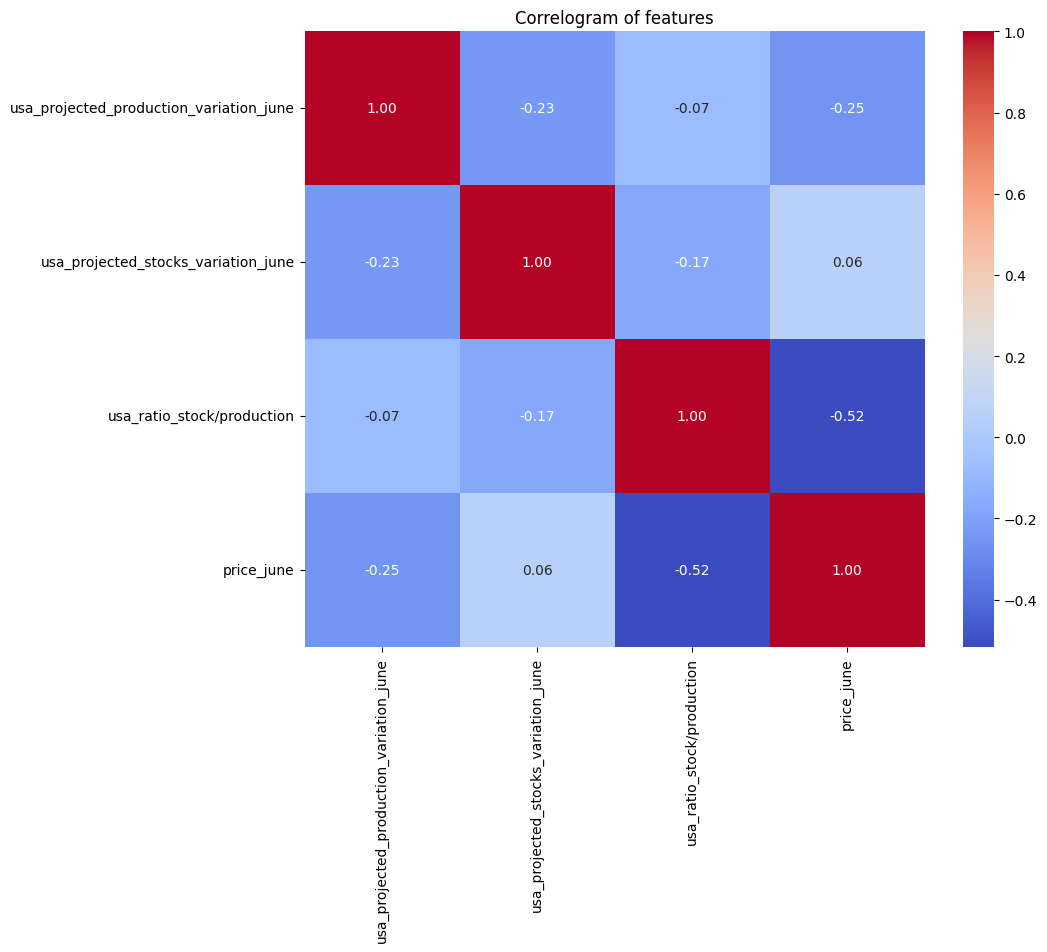

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_final.drop(columns=['year','price_change_july(%)']).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlogram of features')
plt.show()

## Preparing the data

Once the original variables have been examined, the next step is to prepare the data for their subsequent inclusion in the models.

A common practice in predictive modeling is to create new variables that reflect the underlying logic of the subject being studied. Since this project deals with a time series, it is reasonable to expect past observations to have some influence on present values, as they are not entirely independent of one another. In the context of agricultural production, this assumption makes sense because factors such as biotechnology, machinery, infrastructure, and contractual arrangements tend to persist over time and have a considerable impact on production decisions. Consequently, some degree of dependence between different years is to be expected.

Furthermore, the agricultural sector operates within relatively narrow time windows for certain activities, such as planting. These constraints often mean that current decisions are partly driven by considerations regarding future marketing years, rather than solely by short-term conditions. Therefore, past observations may provide valuable information about current developments.

For these reasons, it is appropriate to create additional variables consisting of one-period lagged versions of the existing features, allowing the models to capture and quantify the potential influence of recent past conditions on the present.

In [13]:
df_final['usa_projected_stocks_variation_june(t-1)'] = df_final['usa_projected_stocks_variation_june'].shift(1)
df_final['usa_projected_production_variation_june(t-1)'] = df_final['usa_projected_production_variation_june'].shift(1)
df_final['usa_ratio_stock/production(t-1)'] = df_final['usa_ratio_stock/production'].shift(1)
df_final['price_june(t-1)'] = df_final['price_june'].shift(1)

The updated correlation analysis reveals some strong linear relationships between variables, suggesting that certain features are highly similar and may be capturing overlapping information. Although this is a factor worth considering, as it can affect coefficient estimation in certain models, it does not represent a major concern in this case, since the primary objective is purely predictive rather than explanatory. Furthermore, several machine learning algorithms are not affected by this type of issue.

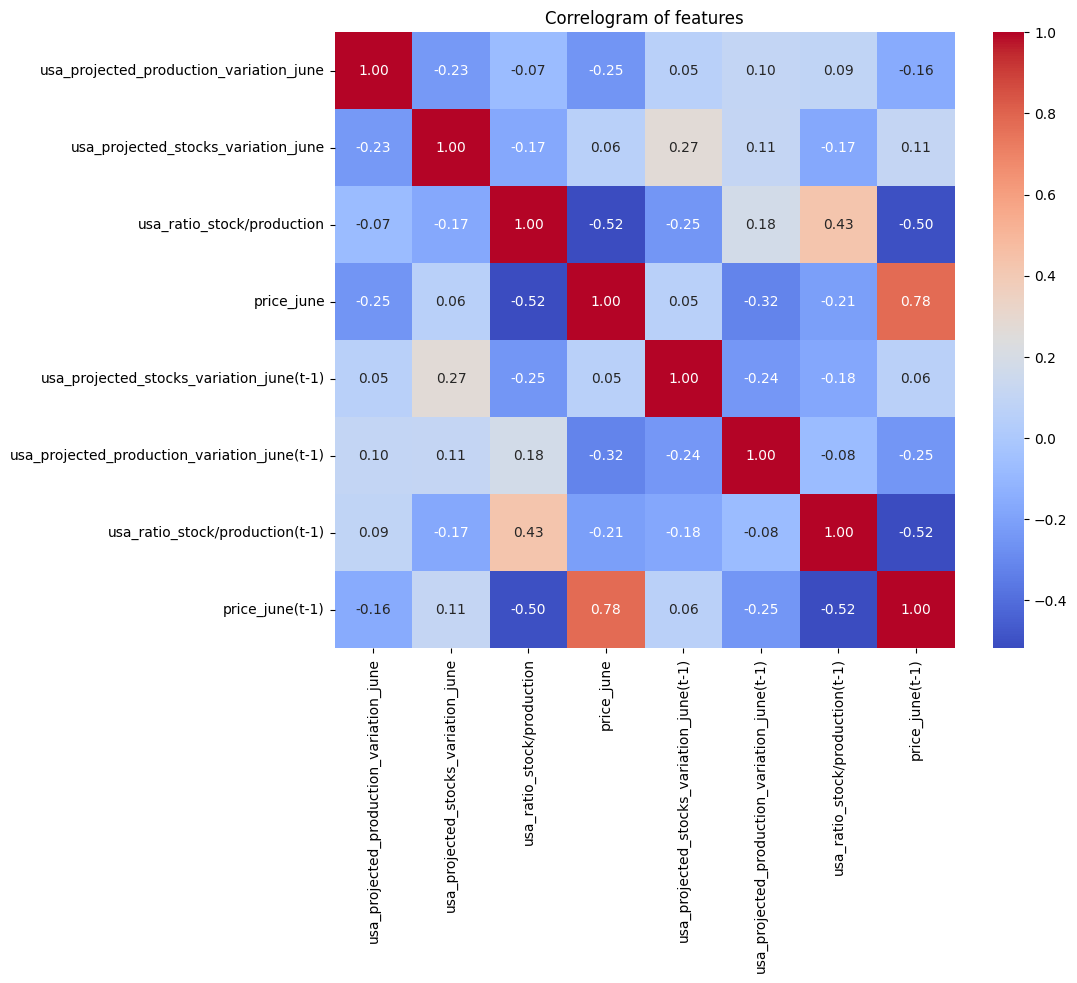

In [14]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_final.drop(columns=['year','price_change_july(%)']).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlogram of features')
plt.show()

So far, no target variable has been introduced, although we know that it must be binary, meaning it can take one of two possible values: *True* or *False*.

To construct this variable, we use monthly price changes, focusing specifically on July. Since the objective is to predict when a price decline will be *significant*, we first need to establish an arbitrary threshold for what constitutes a significant decline. A reasonable choice is -3%.

As previously observed, the median price change for July was close to -3%. Therefore, using this threshold provides a natural way to divide the observations into two classes (significant decline / non-significant decline) with relatively similar numbers of observations.

In [15]:
df_final['<-3%'] = df_final['price_change_july(%)'].map(lambda x: x < -3)

## Predictive models


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, log_loss

### Preprocessing

Before training the models is important to complte the data preprocessing stage. At this point, it is common to transform the variables using different technical and mathematical methods that will improve their predictive performance.



When training machine learning models, it is essential to avoid a common issue known as data leakage, which occurs when information from the training dataset inadvertently contaminates the data used for validation, the other way around.

One potential problem arises when a model is trained using information that would not actually be available at the time a prediction is made. For instance, this project uses a time series spanning the period from 1990 to 2025. It would be incorrect to train a model using data from 2024 and 2025 and then attempt to predict a price decline in 2020, since this would not be feasible in a real-world forecasting scenario. In other words, the model would be given access to information that should not be available to it, thereby overestimating its predictive performance.

To avoid this issue, i employ a validation technique known as walk-forward validation. Under this approach, a block of observations covering a given range of years is used to train the model, which is then evaluated on the immediately following year. The process is repeated by moving the training window forward one year at a time, while the validation year advances accordingly. Given the limited number of observations available for this project, however, we will not use a fixed-size training window. Instead, the model will be trained on all observations available prior to each validation year. Furthermore, the last ten consecutive years will be used for out-of-sample validation.

Another form of data leakage can occur during data preprocessing when transformations are applied to the entire dataset before splitting it into training and test sets. This causes information from the training process to leak into the validation set. For example, this often happens when a variable is standardized using all available observations, since the resulting mean and standard deviation incorporate information from the entire dataset. Applying these statistics to out-of-sample observations introduces information that would not have been available, potentially leading to an overestimation of the model's predictive performance once again. This issue can be easily avoided by using properly designed pipelines, which minimize the risk of inadvertently introducing such errors.

In this project, a logarithmic transformation is applied to soybean futures prices, both at time t and at time t-1. Subsequently, all variables are standardized by subtracting their respective means and dividing by their standard deviations. These preprocessing steps can be particularly useful for improving the predictive performance of certain algorithms, depending on how they operate.

In [17]:
log_scale = Pipeline([
    ("log", FunctionTransformer(np.log)),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("log_scale", log_scale,['price_june',
                                 'price_june(t-1)'
                                 ]),
        ("scaler", StandardScaler(), ['usa_projected_production_variation_june',
                                      'usa_projected_production_variation_june(t-1)',
                                      'usa_projected_stocks_variation_june',
                                      'usa_projected_stocks_variation_june(t-1)',
                                      'usa_ratio_stock/production',
                                      'usa_ratio_stock/production(t-1)'
                                      ])

    ],
    remainder="passthrough"
)



### Algorithms

The algorithms selected for training are among the most widely used in machine learning for classification problems. Three of them are ensemble methods based on simpler models (decision trees). They differ in how these individual trees are constructed and combined, allowing them to achieve greater predictive power than a single decision tree alone. These algorithms are Random Forest, Gradient Boosting, and AdaBoost.

In addition to these three methods, we include an algorithm rooted in classical statistics: Logistic Regression. Although it is not a black-box model, since it allows for some degree of interpretation of the relationships between variables and the predicted outcome, it is also widely used for predictive purposes.


In [18]:
pipe_logistic = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(penalty=None,max_iter=1000,random_state=21))
])

pipe_rf = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(random_state=21))
])

pipe_gb = Pipeline([
    ("preprocess", preprocessor),
    ("model", GradientBoostingClassifier(random_state=21))
])

pipe_ad = Pipeline([
    ("preprocess", preprocessor),
    ("model", AdaBoostClassifier(random_state=21))
])

pipe_dc = Pipeline([
    ("preprocess", preprocessor),
    ("model", DummyClassifier(strategy='most_frequent',random_state=21))
])

In [21]:
models = {
    "Logistic Regression": pipe_logistic,
    "Random Forest": pipe_rf,
    "Gradient Boosting": pipe_gb,
    "Adaboost Classifier": pipe_ad,
    "Dummy Classifier": pipe_dc
    }

selected_features = [
    'usa_projected_production_variation_june',
    'usa_projected_production_variation_june(t-1)',
    'usa_projected_stocks_variation_june',
    'usa_projected_stocks_variation_june(t-1)',
    'usa_ratio_stock/production',
    'usa_ratio_stock/production(t-1)',
    'price_june',
    'price_june(t-1)'
]
target_column = '<-3%'

df_processed = df_final[selected_features + [target_column, 'year']].dropna().copy()

X = df_processed[selected_features]
y = df_processed[target_column]


model_dict = []
acc_dict = []
year_dict = []
losses_dict = []
proba_dict = []

for name, model in models.items():
    for i in range(2016, 2026):

      train_mask = df_processed['year'] < i
      test_mask = df_processed['year'] == i

      X_train, y_train = X[train_mask], y[train_mask]
      X_test, y_test = X[test_mask], y[test_mask]

      model.fit(X_train,y_train)
      y_pred = model.predict(X_test)
      probability = model.predict_proba(X_test)[:,1]

      model_dict.append(name)
      acc_dict.append(accuracy_score(y_test, y_pred))
      year_dict.append(i)
      proba_dict.append(probability)

      if model == pipe_dc:
        losses_dict.append(0)
      else:
        loss = -((y_test.iloc[0])*np.log(probability) + (1-(y_test.iloc[0]))*np.log(1-probability))
        losses_dict.append(loss)


dictionary = {
            "year": year_dict,
            "model": model_dict,
            "accuracy": acc_dict,
            "log_loss": losses_dict,
            "true_probability": proba_dict
            }

Since this is a classification problem, we are interested not only in whether the event will occur, but also in the probability associated with its occurrence. A prediction assigning a 60% probability to the event is not equivalent to one assigning a 90% probability, and these predictions should be penalized differently depending on the actual outcome.

To account for this, we will use an evaluation metric known as *Log Loss*, which measures the logarithmic loss associated with the predicted probabilities. This metric allows us to assess not only whether the model makes correct predictions, but also how accurately it estimates the probability of the event occurring.

The formula:
$$\text{Loss}_i = - [y_i \ln(p_i) + (1 - y_i) \ln(1 - p_i)]$$

Here, $p_i$ represents the predicted probability of the event occurring (a significant price decline during July), while $y_i$ indicates whether the event actually occurred or not (taking binary values). Higher Log Loss values indicate poorer predictive performance.

This metric is particularly useful when complemented by accuracy (using a 50% classification threshold), as the two provide a more comprehensive assessment of how well the models perform in predicting the outcome and help determine which model delivers the best overall performance.

To evaluate model performance, it is common practice to compare them against simpler models that follow basic prediction rules. These models serve as a baseline against which the performance of more sophisticated algorithms can be assessed. One such model is the *Dummy Classifier*, which generates predictions according to a predefined strategy. In this case, it was configured to always predict the most frequent class in the training dataset.

After fitting the models to the training data and evaluating them on the validation set, Logistic Regression clearly outperforms the other algorithms in terms of accuracy, making only one incorrect prediction out of the ten validation observations. The remaining models failed to achieve 60% accuracy, performing only slightly better than the baseline model, the Dummy Classifier, which achieved 40% accuracy.

Furthermore, a comparison of Log Loss values, illustrated through a boxplot, shows that Logistic Regression also achieved better predictive performance, with lower variability across the validation observations. The Dummy Classifier has not obtained any results for the Log Loss score because since its predictions are binary and it is impossible to calculate the logarithm of zero, the formula cannot be used on it.

In [22]:
summary = pd.DataFrame(dictionary)
summary['log_loss'] = summary['log_loss'].apply(lambda x: float(x[0]) if hasattr(x, '__len__') else float(x))
summary['true_probability'] = summary['true_probability'].apply(lambda x: float(x[0]) if hasattr(x, '__len__') else float(x))
group = summary[['accuracy','log_loss','model','year']].groupby(by='model').agg({'accuracy':'mean','log_loss':['mean','std','median'],'year':'count'}).sort_values(by=('accuracy','mean'),ascending=False)
group

accuracy  log_loss                      year
                        mean      mean       std    median count
model                                                           
Logistic Regression      0.9  0.387083  0.469289  0.229023    10
Random Forest            0.6  0.551403  0.363408  0.349583    10
Gradient Boosting        0.5  2.726810  3.864676  0.635423    10
Adaboost Classifier      0.4  0.719822  0.226126  0.727099    10
Dummy Classifier         0.4  0.000000  0.000000  0.000000    10

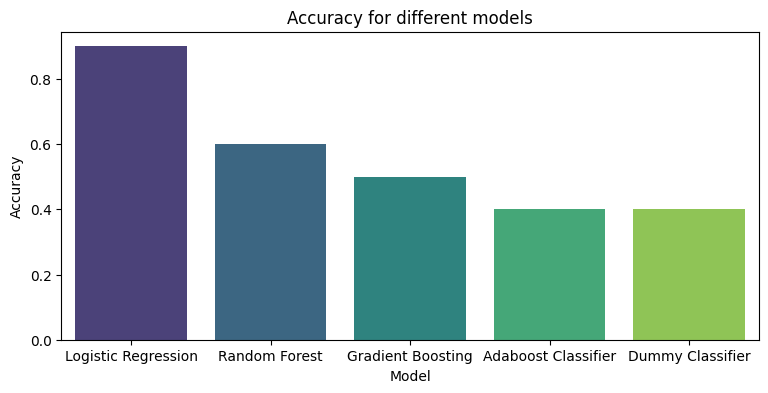

In [23]:
plt.figure(figsize=(9,4))
sns.barplot(data=group['accuracy'],x='model',y='mean',palette='viridis',hue='model',legend=False)
plt.ylabel('Accuracy')
plt.xlabel('Model')
plt.title('Accuracy for different models')
plt.show()

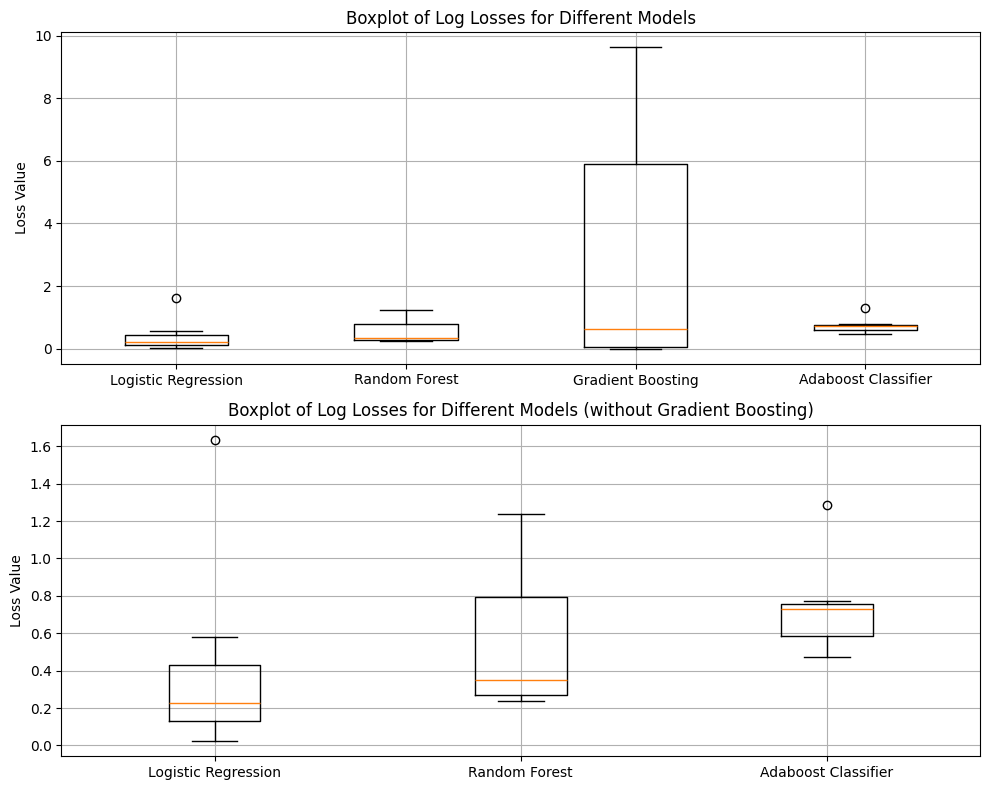

In [24]:
losses_logistic = summary[summary.model == 'Logistic Regression']['log_loss']
losses_randomforest = summary[summary.model == 'Random Forest']['log_loss']
losses_gradientboosting = summary[summary.model == 'Gradient Boosting']['log_loss']
losses_adaboostclassifier = summary[summary.model == 'Adaboost Classifier']['log_loss']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
ax1.boxplot([losses_logistic,
             losses_randomforest,
             losses_gradientboosting,
             losses_adaboostclassifier
             ], tick_labels=['Logistic Regression',
                                                      'Random Forest',
                                                      'Gradient Boosting',
                                                      'Adaboost Classifier'
                                                      ])

ax1.set_title('Boxplot of Log Losses for Different Models')
ax1.set_ylabel('Loss Value')
ax1.grid(True)

ax2.boxplot([losses_logistic,
             losses_randomforest,
             losses_adaboostclassifier], tick_labels=['Logistic Regression',
                                                      'Random Forest',
                                                      'Adaboost Classifier'])

ax2.set_title('Boxplot of Log Losses for Different Models (without Gradient Boosting)')
ax2.set_ylabel('Loss Value')
ax2.grid(True)

plt.tight_layout()
plt.show()

### Regularization

Logistic Regression offers several regularization methods that introduce an additional penalty term to the original loss function being minimized during coefficient estimation. These methods aim to improve the model's predictive performance by reducing the influence of variables with limited predictive contribution, mitigating issues arising from multicollinearity and reducing overfitting.

One of these methods is **Lasso (L1 regularization)**, which can shrink certain coefficients to exactly zero, effectively removing the corresponding variables from the model's predictions.

Another approach is **Ridge (L2 regularization)**, which also reduces coefficient magnitudes but does not shrink them exactly to zero.

Finally, **Elastic Net** combines both approaches by applying a weighted combination of the L1 and L2 penalties described above.

$$\text{Lasso} =L(\beta) + \lambda \sum_{j=1}^{p} |\beta_j|$$

$$\text{Ridge} = L(\beta) + \lambda \sum_{j=1}^{p} \beta_j^2$$

$$\text{Elastic Net} = L(\beta) + \lambda \left[ r \sum_{j=1}^{p} |\beta_j| + (1 - r) \sum_{j=1}^{p} \beta_j^2 \right]$$

Here, $\beta$ represents the estimated model coefficients, $L(\beta)$ is the original Logistic Regression loss function, $\lambda$ is a hyperparameter controlling the strength of the penalty, and r determines the relative weight assigned to the Lasso and Ridge penalties in Elastic Net regularization.

Since Logistic Regression achieved the best predictive performance among the models considered, we can explore whether its performance can be further improved by incorporating these regularization techniques into the original model and evaluating the resulting predictions.

In [25]:
pipe_logistic_l2 = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(penalty='l2',solver= 'liblinear',max_iter=1000,random_state=21))
])
pipe_logistic_l1 = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(penalty='l1',solver= 'liblinear',max_iter=1000,random_state=21))
])
pipe_logistic_en = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(penalty='elasticnet',l1_ratio = 0.5,solver= 'saga',max_iter=1000,random_state=21))
])

In [26]:
best_models = {
    "Logistic Regression": pipe_logistic,
    "Logistic Regression L1": pipe_logistic_l1,
    "Logistic Regression L2": pipe_logistic_l2,
    "Logistic Regression Elasticnet": pipe_logistic_en
    }


model_dict2 = []
acc_dict2 = []
year_dict2 = []
losses_dict2 = []
proba_dict2 = []

for name, model in best_models.items():
  for t in range(2016, 2026):

      train_mask = df_processed['year'] < t
      test_mask = df_processed['year'] == t

      X_train, y_train = X[train_mask], y[train_mask]
      X_test, y_test = X[test_mask], y[test_mask]

      model.fit(X_train,y_train)
      y_pred = model.predict(X_test)
      probability = model.predict_proba(X_test)[:,1]

      model_dict2.append(name)
      acc_dict2.append(accuracy_score(y_test, y_pred))
      year_dict2.append(t)
      proba_dict2.append(probability)

      loss = -((y_test.iloc[0])*np.log(probability) + (1-(y_test.iloc[0]))*np.log(1-probability))
      losses_dict2.append(loss)


dictionary2 = {
            "year": year_dict2,
            "model": model_dict2,
            "accuracy": acc_dict2,
            "log_loss": losses_dict2,
            "true_probability": proba_dict2
            }

After applying the regularization techniques, accuracy remained unchanged across all models. However, Log Loss showed some differences, although relatively small ones.

Using the original, unregularized Logistic Regression as a benchmark, only L2 regularization managed to achieve a comparable average Log Loss, although its median performance was slightly worse. The other two techniques, Lasso and Elastic Net, performed worse in terms of both mean and median Log Loss.

The results look different when focusing on the dispersion of Log Loss values. In this regard, all three regularized models managed to reduce variability compared to the baseline model, with L2 regularization achieving the greatest reduction.


In [27]:
summary2 = pd.DataFrame(dictionary2)
summary2['log_loss'] = summary2['log_loss'].apply(lambda x: float(x[0]) if hasattr(x, '__len__') else float(x))
summary2['true_probability'] = summary2['true_probability'].apply(lambda x: float(x[0]) if hasattr(x, '__len__') else float(x))
summary2[['accuracy','log_loss','model','year']].groupby(by='model').agg({'accuracy':'mean','log_loss':['mean','std','median'],'year':'count'}).sort_values(by=[('accuracy','mean'),('log_loss','median')],ascending=True)

accuracy  log_loss                      year
                                   mean      mean       std    median count
model                                                                      
Logistic Regression                 0.9  0.387083  0.469289  0.229023    10
Logistic Regression L2              0.9  0.398514  0.333559  0.303666    10
Logistic Regression Elasticnet      0.9  0.433654  0.363299  0.340841    10
Logistic Regression L1              0.9  0.458029  0.343901  0.360610    10

Models' graphical comparison

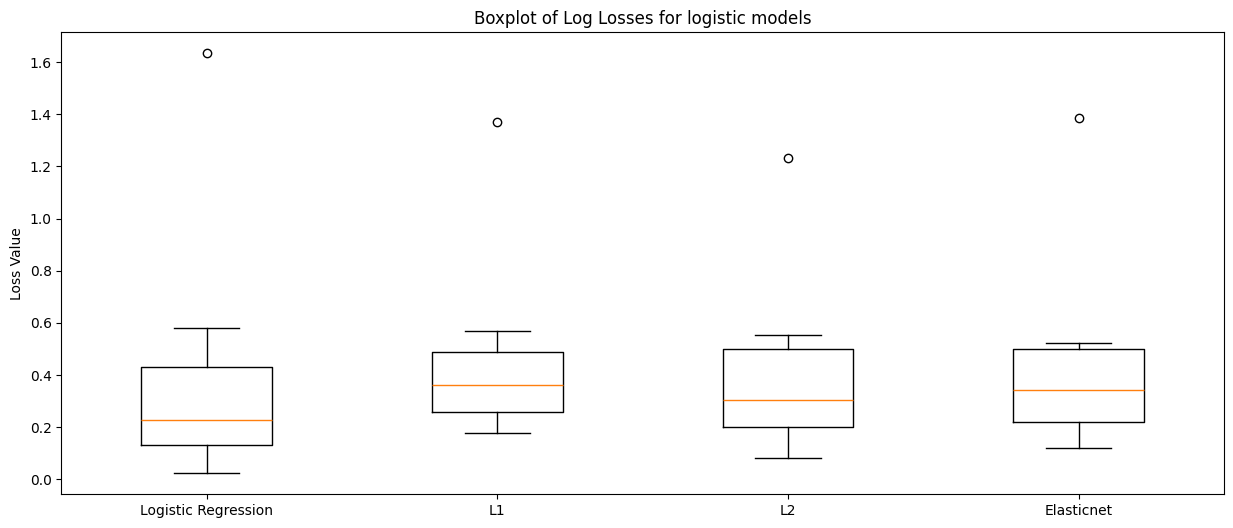

In [28]:
losses_logistic = summary2[summary2.model == 'Logistic Regression']['log_loss']
losses_l1 = summary2[summary2.model == 'Logistic Regression L1']['log_loss']
losses_l2 = summary2[summary2.model == 'Logistic Regression L2']['log_loss']
losses_en = summary2[summary2.model == 'Logistic Regression Elasticnet']['log_loss']


plt.figure(figsize=(15,6))
plt.boxplot(x=[losses_logistic,
               losses_l1,
               losses_l2,
               losses_en
              ], tick_labels=['Logistic Regression',
                              'L1',
                              'L2',
                              'Elasticnet'
                                        ])

plt.title('Boxplot of Log Losses for logistic models')
plt.xticks(rotation=0)
plt.ylabel('Loss Value')
plt.show()

## Conclusions

As previously discussed, Logistic Regression ultimately proved to be the best-performing model for predicting significant price declines during July. Not only did it achieve a high accuracy rate (90%), but it also substantially outperformed the other algorithms considered, while showing a clear improvement over the baseline model.

Building on this result, i attempted to improve the model through regularization techniques, aiming to reduce overfitting and further enhance its predictive performance. Overall, no improvements were achieved in terms of accuracy. However, we were able to identify a model with lower Log Loss dispersion without substantially increasing its average value. This model was Logistic Regression with Ridge (L2) regularization.

Nevertheless, the differences between the models were relatively small, amounting to only a few decimal points in Log Loss, while the most important performance metric, accuracy, remained unchanged.

Based on these results, i conclude that Logistic Regression is a useful approach for addressing the prediction problem considered in this project.
